# Random Walk Model

A random walk accumulates shocks: $X_t=X_{t-1}+\varepsilon_t$, so $X_t=X_0+\sum_{j=1}^{t}\varepsilon_j$. Every shock is permanent in the level, the variance grows like $t\sigma^2$, and first differences recover the stationary innovations.

This notebook follows the note on the random walk: it verifies the worked numerical path, checks the variance growth and forecast-error variance by simulation, adds drift, and contrasts the sample ACF of the level with that of the differences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from statsmodels.tsa.stattools import acf

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3})

# Worked path from the note: X_0 = 5, shocks (1, -2, 0.5, 1.5)
x0 = 5.0
shocks = np.array([1.0, -2.0, 0.5, 1.5])
X = x0 + np.cumsum(shocks)
print("X_1..X_4          :", X)
print("first differences :", np.diff(np.r_[x0, X]), "(recover the shocks)")
print("Var(X_4 | X_0)    :", 4 * 1.0**2, "(= t * sigma^2 with sigma^2 = 1)")
print("point forecast    : every horizon equals X_4 =", X[-1])

X_1..X_4          : [6.  4.  4.5 6. ]
first differences : [ 1.  -2.   0.5  1.5] (recover the shocks)
Var(X_4 | X_0)    : 4.0 (= t * sigma^2 with sigma^2 = 1)
point forecast    : every horizon equals X_4 = 6.0


The path reproduces $X_1,\dots,X_4=6,4,4.5,6$, the differences return the shocks exactly, and the zero-drift forecast is flat at $X_T=6$.

## Variance grows linearly

Simulate many independent paths and compare the empirical cross-sectional variance at each $t$ with $t\sigma^2$. The mean stays at $X_0$ even though individual paths wander.

t= 10  mean=  4.99 (theory 5.0)   var=    9.8 (theory 10)
t= 50  mean=  4.95 (theory 5.0)   var=   49.8 (theory 50)
t=100  mean=  4.91 (theory 5.0)   var=  100.2 (theory 100)
t=200  mean=  5.02 (theory 5.0)   var=  196.8 (theory 200)


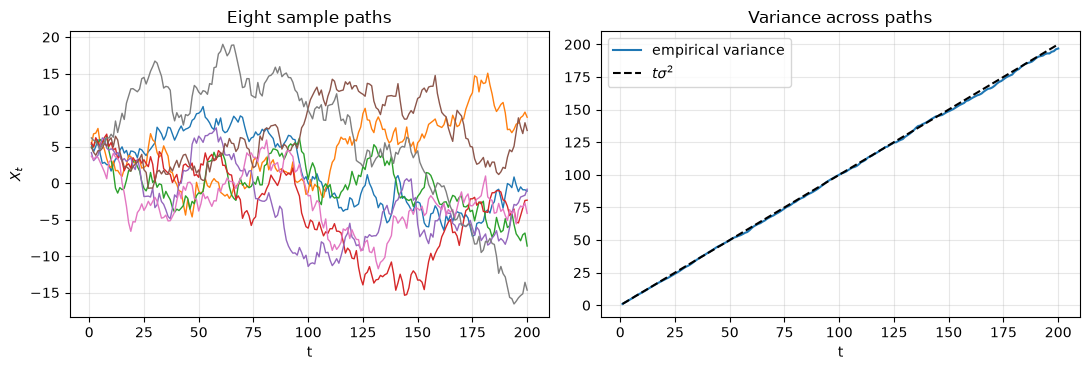

In [2]:
n_paths, T, sigma = 5000, 200, 1.0
eps = rng.normal(0, sigma, size=(n_paths, T))
paths = x0 + np.cumsum(eps, axis=1)          # X_1..X_T for each path
t = np.arange(1, T + 1)

emp_var = paths.var(axis=0, ddof=1)
emp_mean = paths.mean(axis=0)
for k in (10, 50, 100, 200):
    print(f"t={k:3d}  mean={emp_mean[k-1]:6.2f} (theory {x0})   var={emp_var[k-1]:7.1f} (theory {k*sigma**2:.0f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t, paths[:8].T, lw=1)
ax[0].set(title="Eight sample paths", xlabel="t", ylabel="$X_t$")
ax[1].plot(t, emp_var, label="empirical variance")
ax[1].plot(t, t * sigma**2, "k--", label=r"$t\sigma^2$")
ax[1].set(title="Variance across paths", xlabel="t"); ax[1].legend()
plt.tight_layout(); plt.show()

The empirical variance tracks the line $t\sigma^2$ closely, while the mean is flat at $X_0=5$. The growing variance is what violates weak stationarity.

## Forecast uncertainty and drift

From a time-$T$ origin the zero-drift forecast is $X_T$ with error variance $h\sigma^2$; with drift $\delta$ the forecast is $X_T+h\delta$. We check this by simulating futures from the worked path ending at $X_4=6$.

h   var(no drift)  theory   mean(drift)  theory
 1          1.03       1        6.31     6.30
 5          5.01       5        7.53     7.50
10         10.16      10        9.00     9.00
30         30.08      30       15.05    15.00


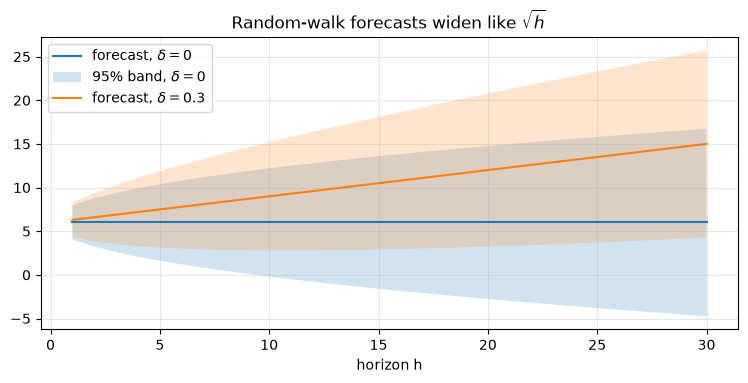

In [3]:
h_max, delta, n_sim = 30, 0.3, 20000
h = np.arange(1, h_max + 1)
XT = X[-1]

fut_eps = rng.normal(0, 1, size=(n_sim, h_max))
fut0 = XT + np.cumsum(fut_eps, axis=1)               # no drift
futd = XT + np.cumsum(delta + fut_eps, axis=1)       # with drift

print("h   var(no drift)  theory   mean(drift)  theory")
for k in (1, 5, 10, 30):
    print(f"{k:2d}  {fut0[:, k-1].var():12.2f}  {k:6d}  {futd[:, k-1].mean():10.2f}  {XT + k*delta:7.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(h, XT + 0 * h, label="forecast, $\\delta=0$")
ax.fill_between(h, XT - 1.96*np.sqrt(h), XT + 1.96*np.sqrt(h), alpha=0.2, label="95% band, $\\delta=0$")
ax.plot(h, XT + delta*h, label=f"forecast, $\\delta={delta}$")
ax.fill_between(h, XT + delta*h - 1.96*np.sqrt(h), XT + delta*h + 1.96*np.sqrt(h), alpha=0.2)
ax.set(title="Random-walk forecasts widen like $\\sqrt{h}$", xlabel="horizon h"); ax.legend()
plt.show()

Forecast-error variance matches $h\sigma^2$, and drift only shifts the centre line to $X_T+h\delta$; it does not change how uncertainty accumulates.

## Level versus differences: sample ACF

The sample ACF of a random walk level decays very slowly, because neighbouring levels share most of their accumulated shocks. The first difference is the innovation sequence, so its ACF is near zero.

max |ACF| of differences, lags 1-20: 0.074 (band ~ 0.062 )
ACF of level at lags 1, 10, 50     : [0.985 0.827 0.18 ]
recovered shocks exactly           : True


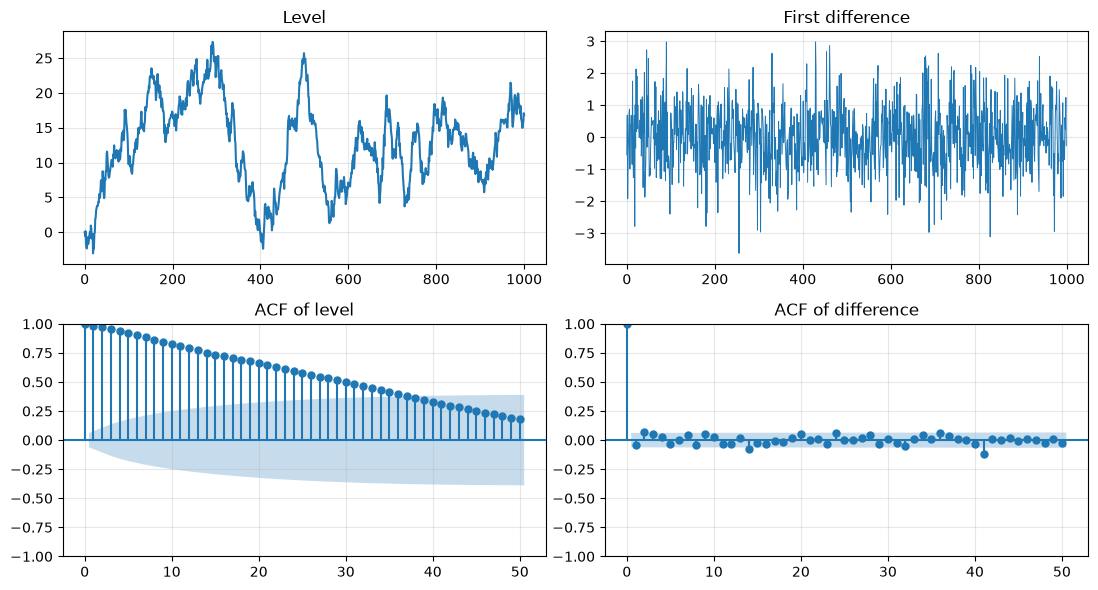

In [4]:
from statsmodels.graphics.tsaplots import plot_acf

N = 1000
Z = rng.normal(0, 1, size=N)
level = np.cumsum(np.r_[0, Z])          # X_0 = 0
dlevel = np.diff(level)

print("max |ACF| of differences, lags 1-20:", np.abs(acf(dlevel, nlags=20)[1:]).max().round(3),
      "(band ~", round(1.96/np.sqrt(len(dlevel)), 3), ")")
print("ACF of level at lags 1, 10, 50     :", acf(level, nlags=50)[[1, 10, 50]].round(3))
print("recovered shocks exactly           :", np.allclose(dlevel, Z))

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
ax[0, 0].plot(level); ax[0, 0].set_title("Level")
ax[0, 1].plot(dlevel, lw=0.7); ax[0, 1].set_title("First difference")
plot_acf(level, lags=50, ax=ax[1, 0], title="ACF of level")
plot_acf(dlevel, lags=50, ax=ax[1, 1], title="ACF of difference")
plt.tight_layout(); plt.show()

The level's ACF stays close to 1 over many lags, a warning that it is not short-memory stationary; the differenced series behaves like white noise with ACF values around zero, of about the size of the $\pm1.96/\sqrt n$ band. Differencing recovers $\varepsilon_t$ exactly, matching $\nabla X_t=\varepsilon_t$ in the note.